# 무엇을 보고 분류하나 — Occlusion + Acoustic Probing

linear은 raw 오디오가 아니라 **XLS-R이 만든 1920-d 임베딩**을 보고 국적을 정합니다.
"그 안에서 뭘 보는지"를 두 방법으로 캡니다.
- **Occlusion(가려보기)**: 입력의 주파수대역/시간구간을 실제로 지우고 그 국적 확률이 얼마나 떨어지나 → 중요한 대역/구간.
- **Acoustic probing**: 임베딩에서 F0/F1/F2/에너지가 얼마나 복원되나(R²) + 그게 국적별로 갈리나(eta²).

⚠️ 26GB 인코더 로드(~67s) + GPU 필요.

In [1]:
import os, sys, json
import numpy as np, torch, torch.nn as nn, soundfile as sf, pandas as pd
from scipy import signal
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
sys.path.insert(0,"$HOME/scripts"); import baseline_common as bc
sys.path.insert(0,"$HOME")
from country_classifier.model import build_model
import parselmouth as pm
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score
fm.fontManager.addfont("$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf")
plt.rcParams["font.family"]=fm.FontProperties(fname="$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf").get_name()
plt.rcParams["axes.unicode_minus"]=False
DEV="cuda"; SR=16000; CROP=5.0

# 빠른 61-class linear head (캐시 feature, z-score)
MF="$NATIONALITY_RUNS/features_fine_811"
z=np.load(MF+"/train.npz",allow_pickle=True); Xtr=z["X"].astype(np.float32); ytr=z["y"].astype(np.int64)
label2id=json.load(open(MF+"/label2id.json",encoding="utf-8")); C=len(label2id)
mean=Xtr.mean(0,keepdims=True); std=Xtr.std(0,keepdims=True)+1e-6
Xt=torch.from_numpy((Xtr-mean)/std); yt=torch.from_numpy(ytr)
head=nn.Linear(1920,C).to(DEV); opt=torch.optim.AdamW(head.parameters(),lr=1e-3,weight_decay=1e-4); lf=nn.CrossEntropyLoss()
for ep in range(15):
    perm=torch.randperm(len(yt))
    for s in range(0,len(yt),8192):
        i=perm[s:s+8192]; opt.zero_grad(); lf(head(Xt[i].to(DEV)),yt[i].to(DEV)).backward(); opt.step()
meanT=torch.from_numpy(mean).to(DEV); stdT=torch.from_numpy(std).to(DEV); Wt=head.weight.detach(); bt=head.bias.detach()
print("head trained")

# 인코더 (activation checkpointing 끄기)
def _disable_ckpt(enc):
    n=0
    for m in enc.modules():
        if hasattr(m,"precheckpoint_forward"): m.forward=m.precheckpoint_forward; n+=1
    return n
model=build_model(backend="fairseq_xlsr",num_classes=C,checkpoint_path="$SPEECH_AI_MODELS/xlsr2_2B_1000k.pt",
                  fairseq_root="$FAIRSEQ_ROOT",freeze_encoder=True).to(DEV).eval()
_disable_ckpt(model.encoder)
try: model.encoder.encoder.layerdrop=0.0
except: pass
ridx=pd.read_csv("$NATIONALITY_DATA/reading_index.csv"); audio_idx=bc.build_audio_index(bc.DEFAULT_AUDIO_ROOT)

def load(path,crop=CROP):
    y,s=sf.read(path); return (y.mean(1) if y.ndim>1 else y).astype(np.float32)[:int(crop*SR)]
def embed(y):
    wav=torch.from_numpy(y)[None].to(DEV); mask=torch.zeros(1,wav.shape[1],dtype=torch.bool,device=DEV)
    with torch.no_grad(), torch.autocast("cuda"):
        f,fmk=model._extract_features(wav,mask); pool=model._pool(f,fmk)
    return pool[0].float().cpu().numpy()
def prob(y,cid):
    wav=torch.from_numpy(y)[None].to(DEV); mask=torch.zeros(1,wav.shape[1],dtype=torch.bool,device=DEV)
    with torch.no_grad(), torch.autocast("cuda"):
        f,fmk=model._extract_features(wav,mask); pool=model._pool(f,fmk)
        return torch.softmax(((pool-meanT)/stdT)@Wt.T+bt,1)[0,cid].item()
def remove_band(y,lo,hi):
    f,t,Z=signal.stft(y,fs=SR,nperseg=512); Z[(f>=lo)&(f<hi),:]=0; _,yr=signal.istft(Z,fs=SR,nperseg=512)
    return yr[:len(y)].astype(np.float32)
def spk_utts(nat,n,seed=0):
    d=ridx[ridx.mother_tongue==nat].sample(frac=1,random_state=seed); seen=set(); out=[]
    for _,r in d.iterrows():
        if r.speaker_id in seen: continue
        p=audio_idx.get(r.fileName)
        if p and os.path.exists(p): out.append(p); seen.add(r.speaker_id)
        if len(out)>=n: break
    return out
print("ready")

head trained


INFO:fairseq.tasks.text_to_speech:Please install tensorboardX: pip install tensorboardX
$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/torch/nn/utils/weight_norm.py:30: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


ready


## 1) Occlusion — 어느 주파수대역 / 시간구간이 중요한가

DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.font_manager:findfont: Matching Noto Sans KR:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniBolIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymBol.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs

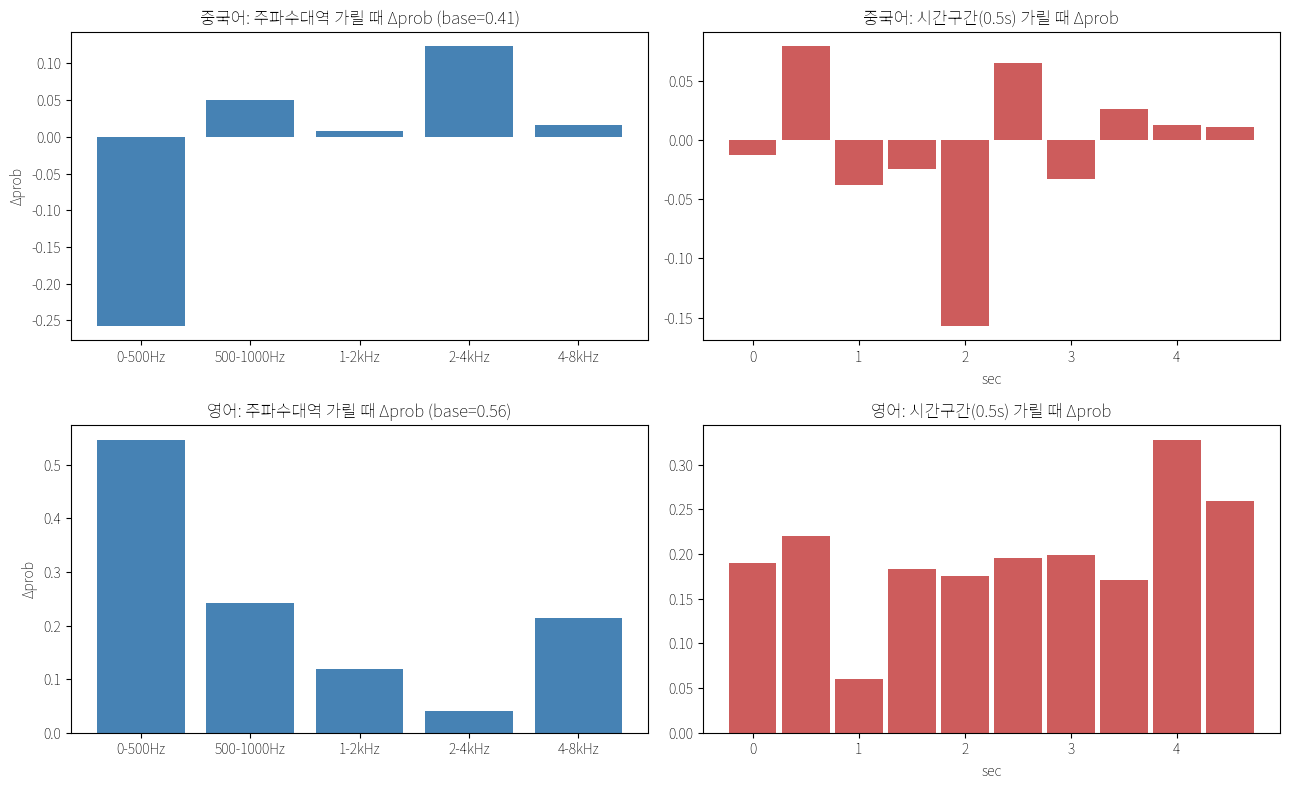

In [2]:
OCC_NATIONS=["중국어","영어"]; N_OCC=12
BANDS=[(0,500),(500,1000),(1000,2000),(2000,4000),(4000,8000)]; TWIN=0.5
fig,axes=plt.subplots(len(OCC_NATIONS),2,figsize=(13,4*len(OCC_NATIONS)),squeeze=False)
for ri,nat in enumerate(OCC_NATIONS):
    cid=label2id[nat]; paths=spk_utts(nat,N_OCC); ntw=int(CROP/TWIN)
    fb=np.zeros(len(BANDS)); tb=np.zeros(ntw); base=0
    for p in paths:
        y=load(p); b=prob(y,cid); base+=b
        for k,(lo,hi) in enumerate(BANDS): fb[k]+=b-prob(remove_band(y,lo,hi),cid)
        for w in range(ntw):
            yy=y.copy(); yy[int(w*TWIN*SR):int((w+1)*TWIN*SR)]=0; tb[w]+=b-prob(yy,cid)
    fb/=len(paths); tb/=len(paths); base/=len(paths)
    lbl=[f"{lo}-{hi}Hz" if hi<=1000 else f"{lo//1000 if lo>=1000 else lo/1000:g}-{hi//1000}kHz" for lo,hi in BANDS]
    axes[ri,0].bar(lbl,fb,color="steelblue"); axes[ri,0].set_title(f"{nat}: 주파수대역 가릴 때 Δprob (base={base:.2f})"); axes[ri,0].set_ylabel("Δprob")
    axes[ri,1].bar(np.arange(ntw)*TWIN,tb,width=TWIN*0.9,color="indianred"); axes[ri,1].set_title(f"{nat}: 시간구간(0.5s) 가릴 때 Δprob"); axes[ri,1].set_xlabel("sec")
plt.tight_layout(); plt.show()

## 2) Acoustic probing — 임베딩이 담은 정도(R²) vs 국적 변별력(eta²)

중국어 done
일본어 done
베트남어 done
태국어 done
몽골어 done
러시아어 done
영어 done
미얀마어 done
R2 {'F0(피치)': 0.62, 'F1': 0.4, 'F2': 0.38, '에너지': 0.84}
eta2 {'F0(피치)': 0.103, 'F1': 0.032, 'F2': 0.055, '에너지': 0.011}


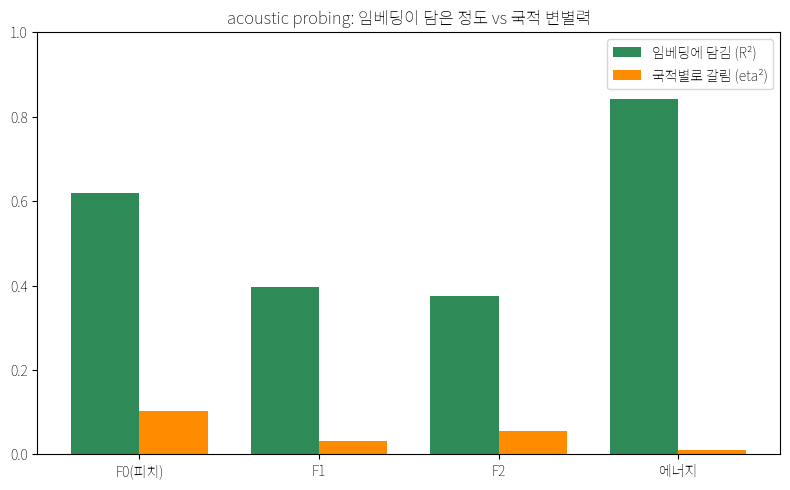

In [3]:
PROBE_NATIONS=["중국어","일본어","베트남어","태국어","몽골어","러시아어","영어","미얀마어"]; N_PR=30
E=[]; F0=[];F1=[];F2=[];EN=[];NAT=[]
for nat in PROBE_NATIONS:
    for p in spk_utts(nat,N_PR,seed=1):
        y=load(p); E.append(embed(y))
        snd=pm.Sound(p)
        if snd.duration>CROP: snd=snd.extract_part(0,CROP)
        pit=snd.to_pitch(); f0=pit.selected_array["frequency"]; ts=pit.xs(); v=f0>0
        form=snd.to_formant_burg(maximum_formant=5500); f1=[];f2=[]
        for t in ts[v]:
            a=form.get_value_at_time(1,t); b=form.get_value_at_time(2,t)
            if a and b and not np.isnan(a) and not np.isnan(b): f1.append(a);f2.append(b)
        F0.append(np.median(f0[v]) if v.any() else np.nan); F1.append(np.median(f1) if f1 else np.nan)
        F2.append(np.median(f2) if f2 else np.nan); EN.append(10*np.log10(np.mean(y**2)+1e-9)); NAT.append(nat)
    print(f"{nat} done")
E=np.array(E); NAT=np.array(NAT)
feats={"F0(피치)":np.array(F0),"F1":np.array(F1),"F2":np.array(F2),"에너지":np.array(EN)}
def eta2(a,g):
    m=~np.isnan(a); a=a[m]; g=g[m]; gm=a.mean()
    ssb=sum(((a[g==u].mean()-gm)**2)*np.sum(g==u) for u in np.unique(g)); sst=((a-gm)**2).sum()
    return ssb/sst if sst>0 else 0
r2={k:max(0,np.mean(cross_val_score(Ridge(alpha=10.0),E[~np.isnan(a)],a[~np.isnan(a)],cv=5,scoring="r2"))) for k,a in feats.items()}
et={k:eta2(a,NAT) for k,a in feats.items()}
print("R2",{k:round(r2[k],2) for k in feats}); print("eta2",{k:round(et[k],3) for k in feats})
x=np.arange(len(feats)); w=0.38
fig,ax=plt.subplots(figsize=(8,5))
ax.bar(x-w/2,[r2[k] for k in feats],w,label="임베딩에 담김 (R²)",color="seagreen")
ax.bar(x+w/2,[et[k] for k in feats],w,label="국적별로 갈림 (eta²)",color="darkorange")
ax.set_xticks(x); ax.set_xticklabels(list(feats)); ax.set_ylim(0,1); ax.legend()
ax.set_title("acoustic probing: 임베딩이 담은 정도 vs 국적 변별력"); plt.tight_layout(); plt.show()

## 3) 같은 문장 · 여러 국적 occlusion 히트맵 — 가리면 어느 클래스로 옮겨가나

같은 낭독 문장을 말한 여러 국적을 모아, 대역을 가렸을 때 **확률이 어느 클래스로 이동하는지** 봅니다.
행=가린 대역, 열=후보 클래스, **빨강 테두리=정답**, 숫자=확률. (국적당 1명 → 화자 운 주의, `PER` 늘려 평균 가능)

문장: 와 생일 축하해요 한국에서는 생일에 미역국을 먹어요 제가 소미 씨를 위해 미역국을 맛있게 만들어 줄게요 | 공유국적: 8


DEBUG:matplotlib.font_manager:findfont: Matching Noto Sans KR:style=normal:variant=normal:weight=normal:stretch=normal:size=7.0.
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniBolIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXSizThreeSymBol.ttf', name='STIXSizeThreeSym', style='normal', variant='normal', weight=700, stretch='normal', size='scalable')) = 10.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXGeneral.ttf', name='STIXGeneral', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.

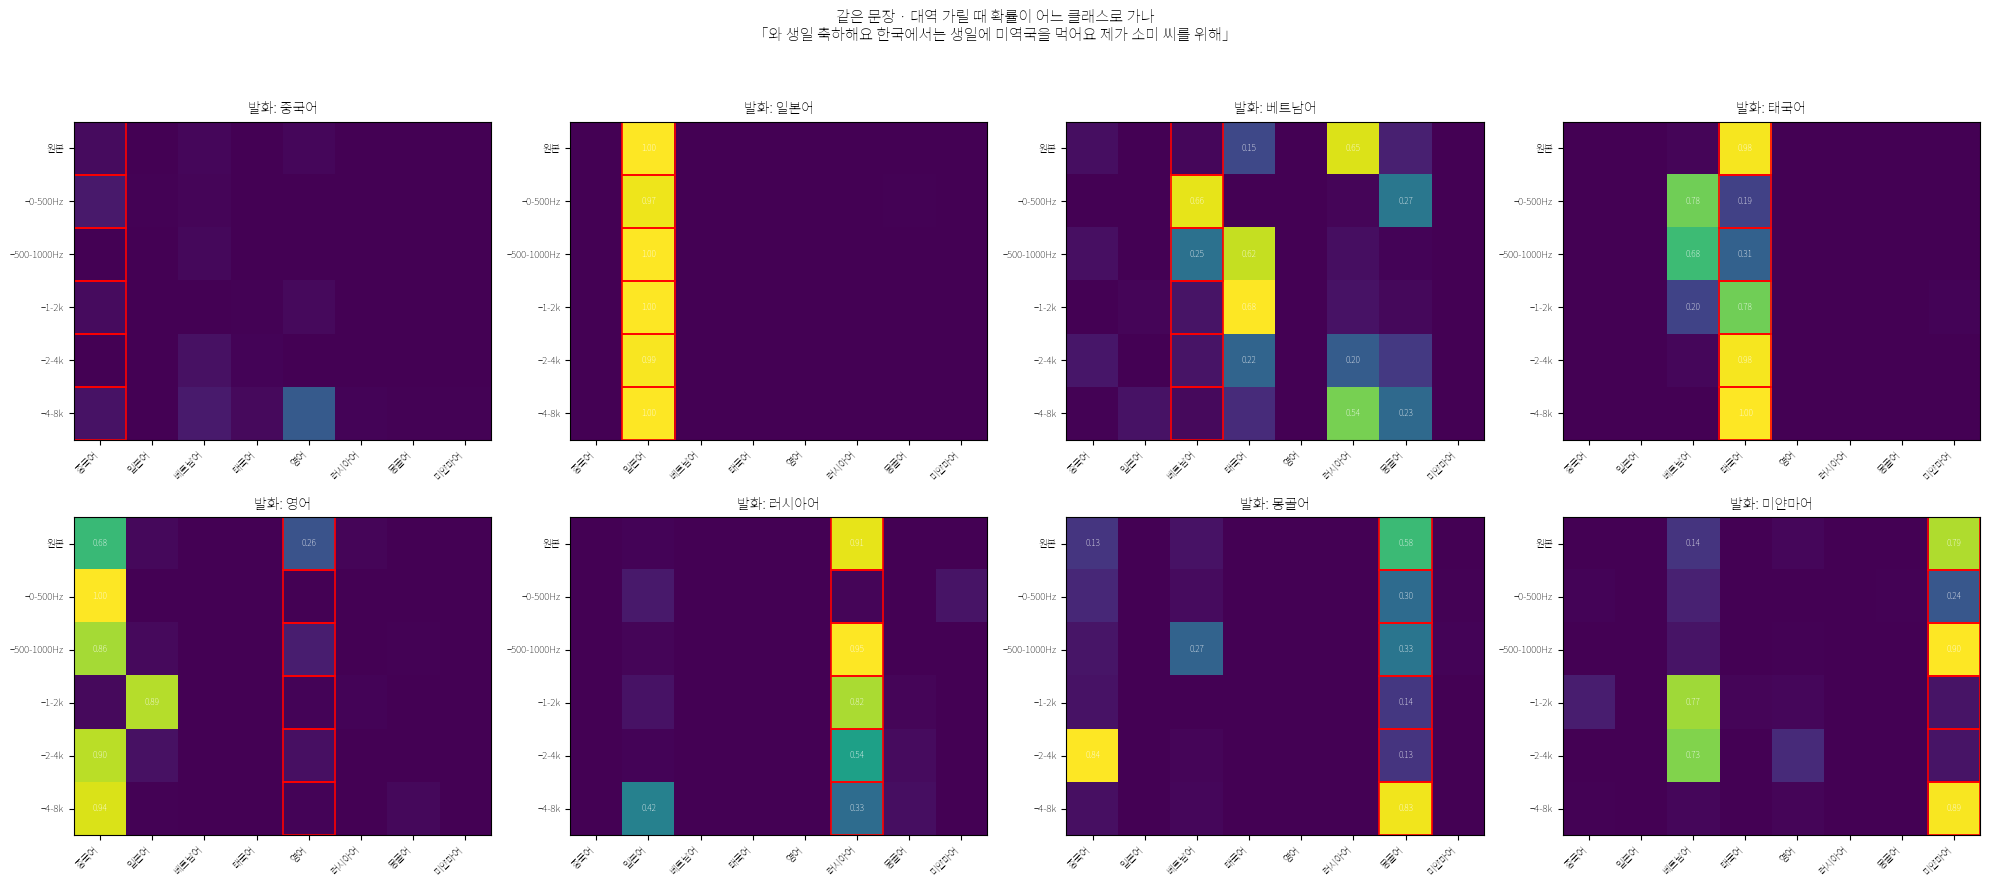

In [4]:
HEAT_NATIONS=["중국어","일본어","베트남어","태국어","영어","러시아어","몽골어","미얀마어"]
HCROP=6.0
def probvec(y):
    wav=torch.from_numpy(y)[None].to(DEV); mask=torch.zeros(1,wav.shape[1],dtype=torch.bool,device=DEV)
    with torch.no_grad(), torch.autocast("cuda"):
        f,fmk=model._extract_features(wav,mask); pool=model._pool(f,fmk)
        return torch.softmax(((pool-meanT)/stdT)@Wt.T+bt,1)[0].float().cpu().numpy()

sub=ridx[ridx.mother_tongue.isin(HEAT_NATIONS)]
gg=sub.groupby("reading_text")["mother_tongue"].nunique().sort_values(ascending=False)
TEXT=gg.index[0]; print("문장:",TEXT,"| 공유국적:",gg.iloc[0])
BANDS=[(0,500),(500,1000),(1000,2000),(2000,4000),(4000,8000)]
conds=["원본"]+[f"−{lo}-{hi}Hz" if hi<=1000 else f"−{lo/1000:g}-{hi//1000}k" for lo,hi in BANDS]
cand=[label2id[n] for n in HEAT_NATIONS]
picks={}
for nat in HEAT_NATIONS:
    for _,r in sub[(sub.reading_text==TEXT)&(sub.mother_tongue==nat)].sample(frac=1,random_state=0).iterrows():
        p=audio_idx.get(r.fileName)
        if p and os.path.exists(p): picks[nat]=p; break
rows=len(picks); ncol=(rows+1)//2
fig,axes=plt.subplots(2,ncol,figsize=(5*ncol,9),squeeze=False); axes=axes.flat
for ax,(nat,p) in zip(axes,picks.items()):
    y=load(p,HCROP); M=[probvec(y)[cand]]+[probvec(remove_band(y,lo,hi))[cand] for lo,hi in BANDS]; M=np.array(M)
    ax.imshow(M,aspect="auto",cmap="viridis",vmin=0,vmax=max(0.3,M.max()))
    ax.set_xticks(range(len(HEAT_NATIONS))); ax.set_xticklabels(HEAT_NATIONS,rotation=45,fontsize=7,ha="right")
    ax.set_yticks(range(len(conds))); ax.set_yticklabels(conds,fontsize=7); ax.set_title(f"발화: {nat}",fontsize=10)
    ti=HEAT_NATIONS.index(nat)
    for rr in range(len(conds)): ax.add_patch(plt.Rectangle((ti-0.5,rr-0.5),1,1,fill=False,edgecolor="red",lw=1.2))
    for rr in range(M.shape[0]):
        for cc in range(M.shape[1]):
            if M[rr,cc]>=0.12: ax.text(cc,rr,f"{M[rr,cc]:.2f}",ha="center",va="center",fontsize=6,color="w")
for ax in list(axes)[rows:]: ax.axis("off")
fig.suptitle(f"같은 문장 · 대역 가릴 때 확률이 어느 클래스로 가나\n「{TEXT[:40]}」",fontsize=11)
fig.tight_layout(rect=[0,0,1,0.95]); plt.show()

## 해석
- **Occlusion**: 국적마다 의존 대역이 다름(예 영어=0–1kHz, 중국어=2–4kHz). 모델은 분명 주파수 정보를 씀.
- **Probing**: 임베딩은 에너지(R²~0.84)·피치(~0.62)·포먼트(~0.4)를 풍부히 담지만, 그것들은 **국적별로 거의 안 갈림(eta²<0.1)**.
- → 분류는 "피치/포먼트 같은 단순 음향"이 아니라 **임베딩의 추상적 조합**에 의존하고, 그 국적 신호가 약함. (t-SNE·LTAS와 같은 결론)